# FXA logS: faithfulness results

In [1]:
from mol_faith.notebooks.results_analysis.shared import (
    REAL_WORLD_DATASETS,
    REAL_WORLD_RESULTS,
    REAL_WORLD_TARGET_COLORS,
    calculate_stats_by_method_target,
    combine_and_calculate_variance,
    compute_correlation_summary,
    compute_k_effect,
    create_grouped_boxplot,
    load_raw_data,
    load_raw_data_all_thres,
    pair_xai_methods,
    plot_alpha_plus_times_s_value,
    plot_boxplot_grid_by_model,
    plot_correlation_heatmap,
    plot_k_effect_bars,
    plot_negative_deviations,
    plot_std_by_method_target,
    process_fidelity_df,
)

In [2]:
DATASET = 'FXA_logS'
FOLDER, TARGET_NAME = REAL_WORLD_DATASETS[DATASET]
BASE_DIR = REAL_WORLD_RESULTS / FOLDER
OUTPUT_DIR = BASE_DIR / 'result_plots'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Load data

In [3]:
fid_df = process_fidelity_df(load_raw_data(BASE_DIR, TARGET_NAME))
fid_all_thres_df = process_fidelity_df(load_raw_data_all_thres(BASE_DIR, TARGET_NAME))
target_data = {DATASET: fid_df}

logs: 16,891 rows | models ['CNN', 'GAT', 'GCN', 'GIN', 'Transformer'] | methods ['gnn_explainer', 'grad_cam', 'graph_mask', 'guided_grad_cam', 'integrated_gradients', 'kernel_shap', 'lime', 'random_explanation', 'shap_sampling'] | thresholds [0.2]
14,391 rows | {'faithful': 9537, 'unfaithful': 4854} | normalized_fid in [-1.000, 1.000]


logs: 152,019 rows | models ['CNN', 'GAT', 'GCN', 'GIN', 'Transformer'] | methods ['gnn_explainer', 'grad_cam', 'graph_mask', 'guided_grad_cam', 'integrated_gradients', 'kernel_shap', 'lime', 'random_explanation', 'shap_sampling'] | thresholds [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
129,519 rows | {'faithful': 82261, 'unfaithful': 47258} | normalized_fid in [-1.000, 1.000]


## Fid+ by xAI method and model

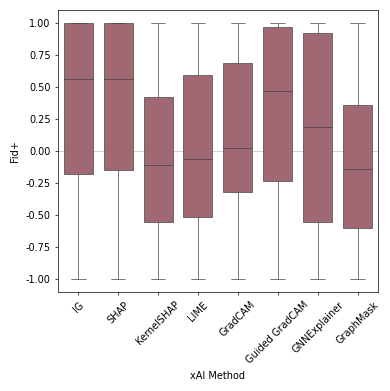

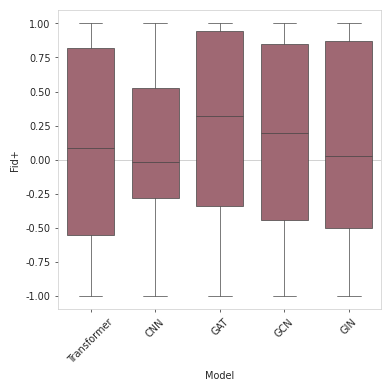

In [4]:
for group_col in ('explanation_method', 'model'):
    create_grouped_boxplot(target_data, value_col='normalized_fid', group_col=group_col, figsize=(4, 4),
                           target_colors=REAL_WORLD_TARGET_COLORS, output_dir=OUTPUT_DIR)

## xAI methods per model

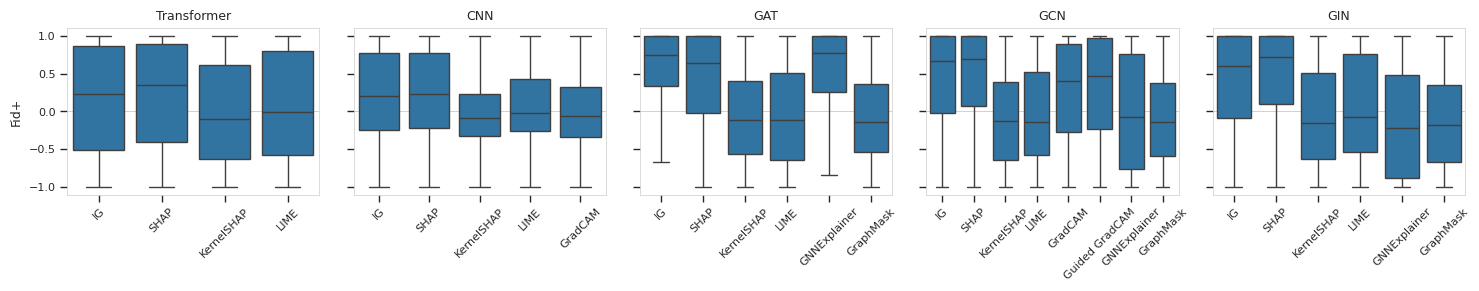

In [5]:
plot_boxplot_grid_by_model(fid_df, output_dir=OUTPUT_DIR);

## Summary table & standard deviation

In [6]:
variance_df = combine_and_calculate_variance(target_data)
variance_df

,model,explanation_method,target,n,mean,median,std,var
5,GAT,GNNExplainer,FXA_logS,500,0.505,0.778,0.623,0.388
7,GAT,IG,FXA_logS,500,0.512,0.750,0.608,0.370
24,GIN,SHAP,FXA_logS,500,0.455,0.718,0.651,0.424
18,GCN,SHAP,FXA_logS,500,0.436,0.687,0.647,0.418
15,GCN,IG,FXA_logS,500,0.413,0.670,0.660,0.436
10,GAT,SHAP,FXA_logS,500,0.414,0.635,0.642,0.412
21,GIN,IG,FXA_logS,500,0.381,0.600,0.667,0.445
14,GCN,Guided GradCAM,FXA_logS,391,0.272,0.465,0.703,0.494
12,GCN,GradCAM,FXA_logS,500,0.244,0.408,0.679,0.461
28,Transformer,SHAP,FXA_logS,500,0.191,0.350,0.730,0.533


In [7]:
calculate_stats_by_method_target(target_data)

,explanation_method,target,n,median,std,var
0,GNNExplainer,FXA_logS,1500,0.186422,0.751380,0.564572
1,GradCAM,FXA_logS,1000,0.020309,0.640568,0.410327
2,GraphMask,FXA_logS,1500,-0.144039,0.653219,0.426695
3,Guided GradCAM,FXA_logS,391,0.465403,0.703102,0.494353
4,IG,FXA_logS,2500,0.563177,0.677177,0.458568
5,KernelSHAP,FXA_logS,2500,-0.110620,0.652236,0.425412
6,LIME,FXA_logS,2500,-0.066839,0.678350,0.460158
7,SHAP,FXA_logS,2500,0.562528,0.667994,0.446216


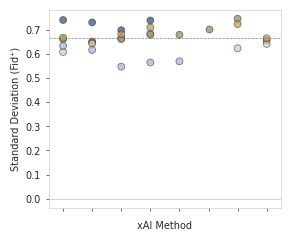

In [8]:
plot_std_by_method_target(variance_df, output_dir=OUTPUT_DIR);

## Parameter k analysis

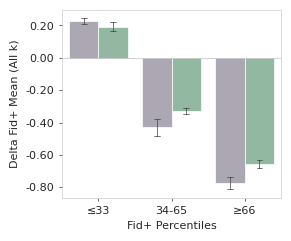

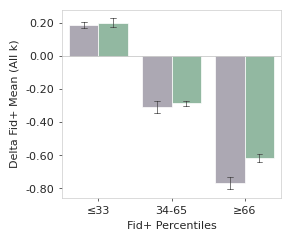

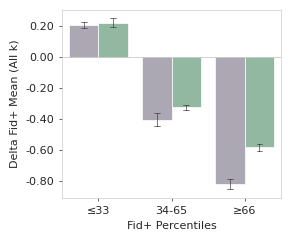

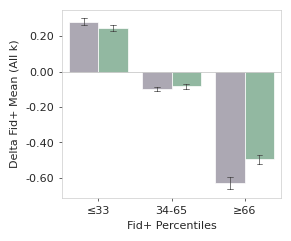

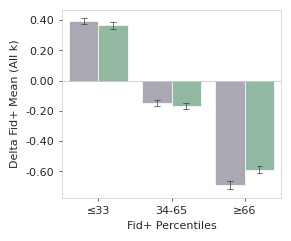

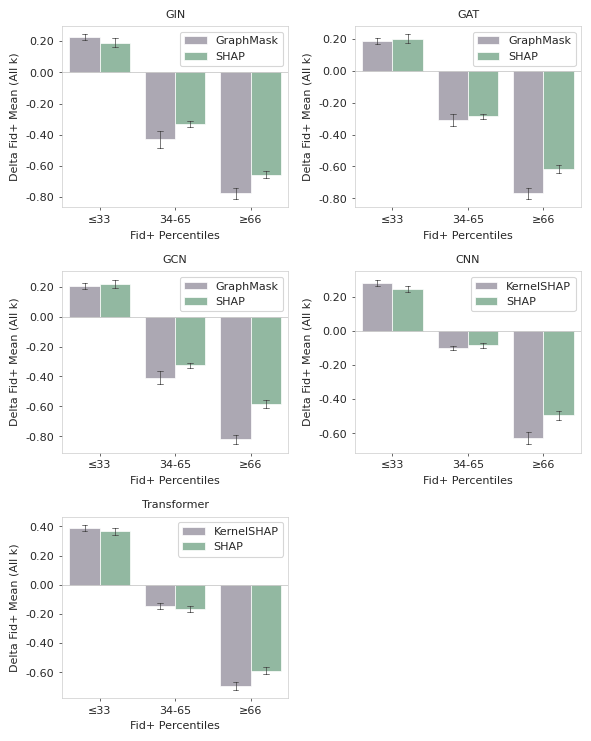

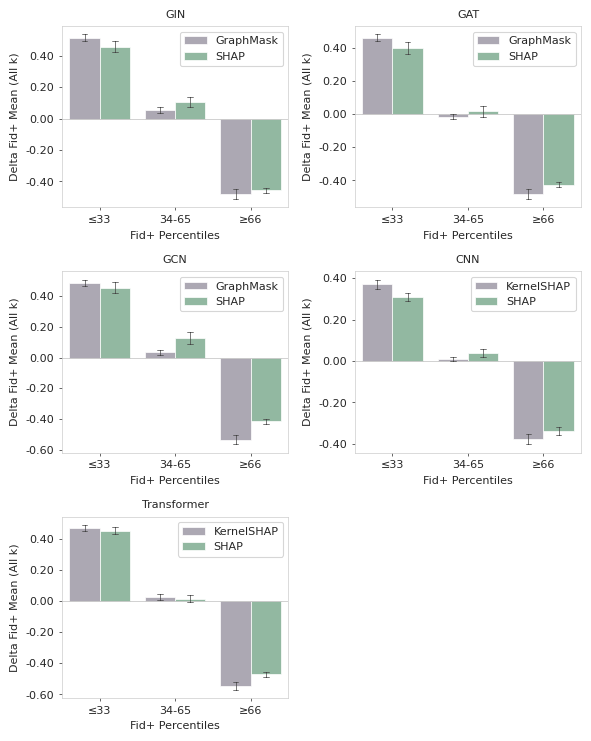

In [9]:
k_effect_df = compute_k_effect(fid_all_thres_df)
plot_k_effect_bars(k_effect_df, OUTPUT_DIR)

### Negative deviation

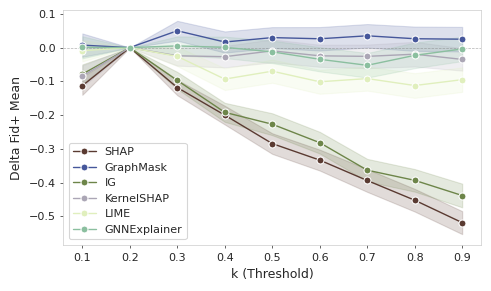

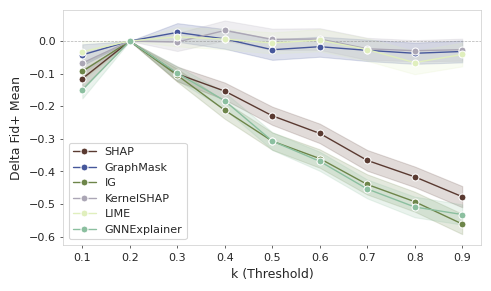

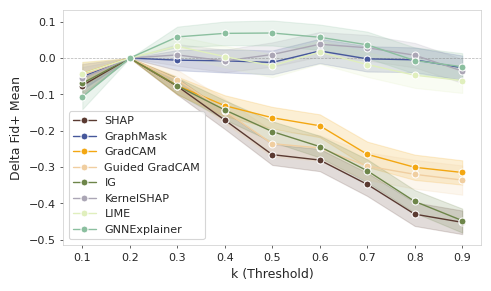

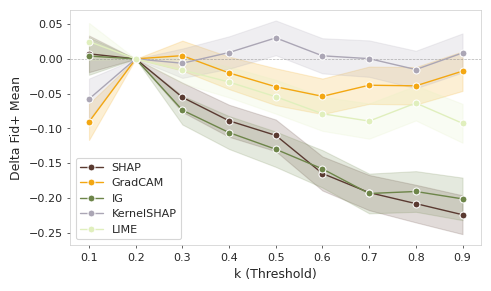

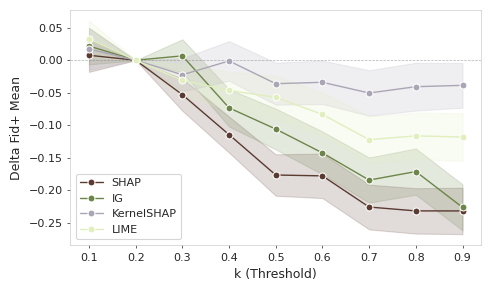

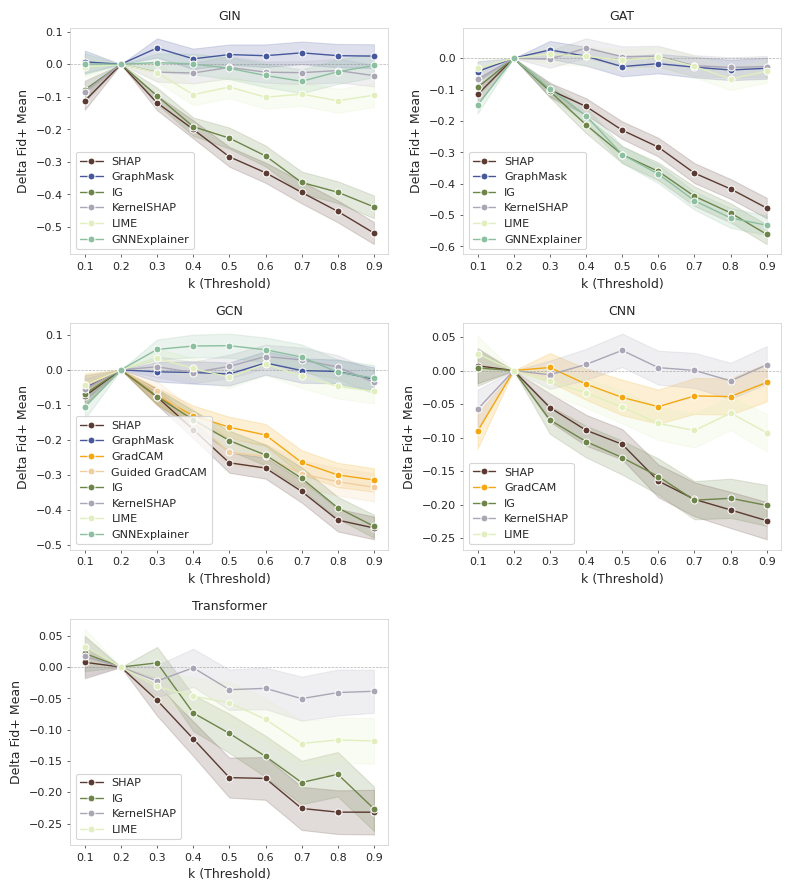

In [10]:
plot_negative_deviations(k_effect_df, OUTPUT_DIR)

## IG vs SHAP agreement

Per-molecule Normalized Fid+ of `integrated_gradients` and `shap_sampling` (same model, smiles, data split) are paired and correlated, to see whether "hard to explain" molecules are intrinsic to the molecule/model or an artifact of the xAI method.

,task,model,n,pearson_r,pearson_p,spearman_r,spearman_p
0,FXA_logS,CNN,500,0.746798,2.890410e-90,0.768847,8.961254e-99
1,FXA_logS,GAT,500,0.732426,3.516001e-85,0.800099,1.322094e-112
2,FXA_logS,GCN,500,0.641944,2.006447e-59,0.699758,9.207459e-75
3,FXA_logS,GIN,500,0.548529,1.272381e-40,0.640767,3.807443e-59
4,FXA_logS,Transformer,500,0.714466,2.851794e-79,0.755649,1.428099e-93


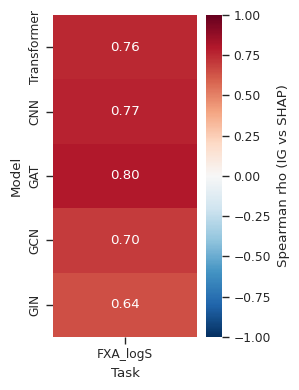

In [12]:
ig_shap_df = pair_xai_methods(fid_df).assign(task=DATASET)
ig_shap_corr_df = compute_correlation_summary(ig_shap_df, ['task', 'model'], 'normalized_fid_ig', 'normalized_fid_shap')
plot_correlation_heatmap(ig_shap_corr_df, output_dir=OUTPUT_DIR)
ig_shap_corr_df

### KernelSHAP vs SHAP agreement

,task,model,n,pearson_r,pearson_p,spearman_r,spearman_p
0,FXA_logS,CNN,500,0.361933,6.388005e-17,0.356573,1.949097e-16
1,FXA_logS,GAT,500,0.273008,5.377259e-10,0.312606,8.513363e-13
2,FXA_logS,GCN,500,0.307669,2.009847e-12,0.311348,1.061256e-12
3,FXA_logS,GIN,500,0.303861,3.856163e-12,0.348851,9.373381e-16
4,FXA_logS,Transformer,500,0.462455,7.307782e-28,0.499504,6.512668e-33


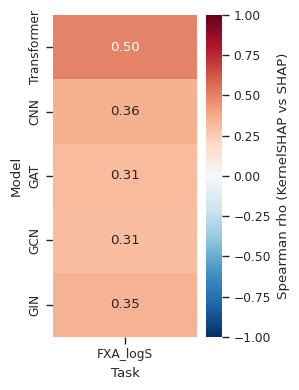

In [13]:
kernel_shap_df = pair_xai_methods(fid_df, method_a='kernel_shap', label_a='kernel_shap').assign(task=DATASET)
kernel_shap_corr_df = compute_correlation_summary(
    kernel_shap_df, ['task', 'model'], 'normalized_fid_kernel_shap', 'normalized_fid_shap'
)
plot_correlation_heatmap(kernel_shap_corr_df, cbar_label='Spearman rho (KernelSHAP vs SHAP)', output_dir=OUTPUT_DIR,
                         filename='kernel_shap_vs_shap_correlation_heatmap')
kernel_shap_corr_df

## Model comparison

In [ ]:
# comparison_csv = BASE_DIR / 'multi_model_comparison.csv'
# format_multi_model_comparison_table(comparison_csv)

In [ ]:
# print(format_latex_model_comparison_table(
#     comparison_csv,
#     caption='Model performance for the FXA logS task.',
#     label='tab:model_perf_fxa_logs',
# ))